In [1]:
from datasets import load_dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

/home/pasali/anaconda3/envs/myenv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
dataset = load_dataset(
    "Yelp/yelp_review_full",
    split="train",
    streaming=True
)

In [4]:
sample = next(iter(dataset))

print(sample)

{'label': 4, 'text': "dr. goldberg offers everything i look for in a general practitioner.  he's nice and easy to talk to without being patronizing; he's always on time in seeing his patients; he's affiliated with a top-notch hospital (nyu) which my parents have explained to me is very important in case something happens and you need surgery; and you can get referrals to see specialists without having to see him first.  really, what more do you need?  i'm sitting here trying to think of any complaints i have about him, but i'm really drawing a blank."}


In [5]:
for i, sample in enumerate(dataset, start=1):
    print(f"Yorum {i}")
    print("Label:", sample["label"])
    print("Text:", sample["text"])
    print("-" * 50)

    if i == 5:
        break

Yorum 1
Label: 4
Text: dr. goldberg offers everything i look for in a general practitioner.  he's nice and easy to talk to without being patronizing; he's always on time in seeing his patients; he's affiliated with a top-notch hospital (nyu) which my parents have explained to me is very important in case something happens and you need surgery; and you can get referrals to see specialists without having to see him first.  really, what more do you need?  i'm sitting here trying to think of any complaints i have about him, but i'm really drawing a blank.
--------------------------------------------------
Yorum 2
Label: 1
Text: Unfortunately, the frustration of being Dr. Goldberg's patient is a repeat of the experience I've had with so many other doctors in NYC -- good doctor, terrible staff.  It seems that his staff simply never answers the phone.  It usually takes 2 hours of repeated calling to get an answer.  Who has time for that or wants to deal with it?  I have run into this problem 

In [6]:
for i, sample in enumerate(dataset, start=1):
    print(f"Yorum {i}")
    print("stars:", sample["label"] + 1)
    print("Text:", sample["text"])
    print("-" * 50)

    if i == 5:
        break

Yorum 1
stars: 5
Text: dr. goldberg offers everything i look for in a general practitioner.  he's nice and easy to talk to without being patronizing; he's always on time in seeing his patients; he's affiliated with a top-notch hospital (nyu) which my parents have explained to me is very important in case something happens and you need surgery; and you can get referrals to see specialists without having to see him first.  really, what more do you need?  i'm sitting here trying to think of any complaints i have about him, but i'm really drawing a blank.
--------------------------------------------------
Yorum 2
stars: 2
Text: Unfortunately, the frustration of being Dr. Goldberg's patient is a repeat of the experience I've had with so many other doctors in NYC -- good doctor, terrible staff.  It seems that his staff simply never answers the phone.  It usually takes 2 hours of repeated calling to get an answer.  Who has time for that or wants to deal with it?  I have run into this problem 

# Yelp Review Full — Dataset Analysis

## 1. Dataset Overview

Bu projede Hugging Face üzerinden Yelp Review Full veri seti kullanılmıştır.

- Dataset: Yelp Review Full
- Language: English
- Training Samples: 650,000
- Test Samples: 50,000
- Number of Classes: 5
- Features: text, label
- Loading Method: Streaming

## 2. Dataset Structure

Veri seti iki sütundan oluşmaktadır:

- text: Kullanıcının yazdığı yorum.
- label: Yorumun 0 ile 4 arasındaki sınıf etiketi.

Veri setindeki beş sınıf dengeli dağıtılmıştır.

## 3. Label Mapping

Dataset etiketleri 0-4 arasında olmasına rağmen gerçek yıldız değerleri 1-5 arasındadır.

| Label | Stars |
|-------|-------|
| 0 | 1 |
| 1 | 2 |
| 2 | 3 |
| 3 | 4 |
| 4 | 5 |

Dönüşüm formülü:

stars = label + 1

İlk beş yorum üzerinde dönüşüm doğrulanmıştır.

## 4. Data Exploration

Veri seti streaming yöntemiyle yüklenmiştir.

İlk beş yorum incelenmiş ve text ile label alanları kontrol edilmiştir.

Bütün veri seti belleğe alınmamıştır.

Orijinal test verisi kullanılmamıştır.

## 5. Dataset Source and License

Dataset Source:
https://huggingface.co/datasets/Yelp/yelp_review_full

Dataset Card:
https://huggingface.co/datasets/Yelp/yelp_review_full/blob/main/README.md

License: Yelp Dataset License

License Terms:
https://s3-media3.fl.yelpcdn.com/assets/srv0/engineering_pages/bea5c1e92bf3/assets/vendor/yelp-dataset-agreement.pdf

Veri setinin kullanımı Yelp'in lisans koşullarına tabidir.
Verilerin yeniden dağıtılması ve ticari kullanımına ilişkin
kısıtlamalar dikkate alınmalıdır.

In [7]:
dataset = load_dataset(
    "Yelp/yelp_review_full",
    split="train",
    streaming=True
)

dataset = dataset.shuffle(
    seed=42,
    buffer_size=10000
)

In [8]:
samples = []

class_counts = {i: 0 for i in range(5)}

In [10]:
for example in dataset:

    label = example["label"]

    if(class_counts[label] < 200):
        samples.append(example)
        class_counts[label] += 1

    # Sınıf sayacını güncelle.

    if all(count == 200 for count in class_counts.values()):
        break   


print("Total Samples:", len(samples))
print(class_counts)

Total Samples: 1000
{0: 200, 1: 200, 2: 200, 3: 200, 4: 200}


In [11]:
df = pd.DataFrame(samples)
df["stars"] = df["label"] + 1

In [12]:
print(df.shape)
print(df.head())
print(df["stars"].value_counts().sort_index())

(1000, 3)
   label                                               text  stars
0      0  we are familiar with Popey's (West coast versi...      1
1      2  Good chicken salad, but wheat bread was ordina...      3
2      1  Fish out of water here when it comes to hardwa...      2
3      1  2 stars only because the service was good.  Fo...      2
4      2  This is absolutely drunk food. For a $5 credit...      3
stars
1    200
2    200
3    200
4    200
5    200
Name: count, dtype: int64


In [13]:
from pathlib import Path

data_path = Path("../data/yelp_sample_1000.csv")

data_path.parent.mkdir(parents=True, exist_ok=True)

df.to_csv(data_path, index=False, encoding="utf-8")

df_check = pd.read_csv(data_path)

print("CSV Shape:", df_check.shape)
print("\nFirst 5 Rows:")
print(df_check.head())

print("\nStars Distribution:")
print(df_check["stars"].value_counts().sort_index())

CSV Shape: (1000, 3)

First 5 Rows:
   label                                               text  stars
0      0  we are familiar with Popey's (West coast versi...      1
1      2  Good chicken salad, but wheat bread was ordina...      3
2      1  Fish out of water here when it comes to hardwa...      2
3      1  2 stars only because the service was good.  Fo...      2
4      2  This is absolutely drunk food. For a $5 credit...      3

Stars Distribution:
stars
1    200
2    200
3    200
4    200
5    200
Name: count, dtype: int64


In [14]:
total_reviews = len(df)

missing_labels = df["label"].isna().sum()

empty_texts = df["text"].fillna("").str.strip().eq("").sum()

print("Toplam yorum:", total_reviews)
print("Boş metin:", empty_texts)
print("Eksik etiket:", missing_labels)

Toplam yorum: 1000
Boş metin: 0
Eksik etiket: 0


In [15]:
duplicate_reviews = df["text"].duplicated().sum()

df["word_count"] = df["text"].str.split().str.len()

avg_words = df["word_count"].mean()
min_words = df["word_count"].min()
max_words = df["word_count"].max()

print("Duplicate yorum:", duplicate_reviews)
print("Ortalama kelime sayısı:", round(avg_words, 2))
print("Minimum kelime sayısı:", min_words)
print("Maksimum kelime sayısı:", max_words)

Duplicate yorum: 0
Ortalama kelime sayısı: 131.2
Minimum kelime sayısı: 2
Maksimum kelime sayısı: 847


In [16]:
review_samples = (
    df.groupby("stars", group_keys=False)
      .sample(n=3, random_state=42)
      .sort_values("stars")
)

for _, row in review_samples.iterrows():
    print(f"⭐ Stars: {row['stars']}")
    print(f"Review: {row['text']}")
    print("-" * 60)

⭐ Stars: 1
Review: Pittsburgh has a shortage of riverfront dining, so this place wins points for ambience on a nice warm day. Have a drink and enjoy the deck, but save your dining budget for somewhere else.  The menu is blah and the food is also.\n\nI recently had lunch here, and the waitress first forgot my meal entirely, bringing food to everyone else at the table.  When I reminded her, she returned with my clam chowder, spilled it, didn't apologize, and didn't clean it up.  All that would have been forgiven if the soup had been any good.
------------------------------------------------------------
⭐ Stars: 1
Review: Buckhead Saloon; The Worst Jack-hole in Charlotte, North Carolina.\n\nBetween the overpriced bottled beer past its expiration date to the broken glass and urine on the floor to the snooty effeminate manager, this place should be avoided at all costs, unless your goal is to catch hepatitis. \nThe one time prior I visited this establishment I was let in with no cover even 

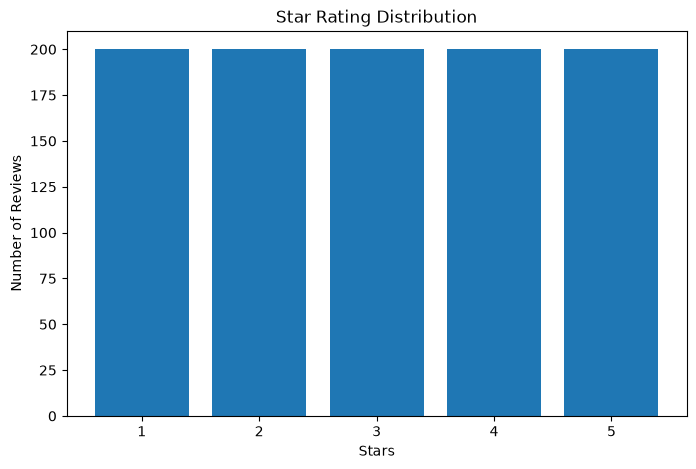

In [19]:
star_counts = df["stars"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

plt.bar(star_counts.index, star_counts.values)

plt.xlabel("Stars")
plt.ylabel("Number of Reviews")
plt.title("Star Rating Distribution")

plt.xticks([1, 2, 3, 4, 5])
plt.show()